# Figure 2 B — replay / non-replay examples and the example d2 curve

Each panel is saved to `../figure_output/<Fig>/`.

In [1]:
# Data: ../csv/Fig2_B_replay_examples/
from pathlib import Path
import pandas as pd
CSV = Path('..') / 'csv' / 'Fig2_B_replay_examples'


def read_csv(name, **kw):
    """A table of this notebook (round_trip: the floats exactly as written)."""
    return pd.read_csv(CSV / name, float_precision='round_trip', **kw)

import os, sys
sys.path.insert(0, os.path.abspath('.'))   # figure_scripts/
import final_figs as F                     # print styles, saving, stars

## Fig 2B — replay and non-replay SWR examples

PPP21 day 4: significant replay event 1731 and non-significant event 934, from the first-submission notebook `Previous_Rv1/figure_scripts/Fig2_B_Example_replay.ipynb`: LFP (±0.1 s around the event centre) above the decoded posterior (10 ms bins) with the replay's line fit. Position 0–145 cm over the 100 decoded bins.

saved figure_output\Fig2\Fig2_B_replay_examples.svg / .png


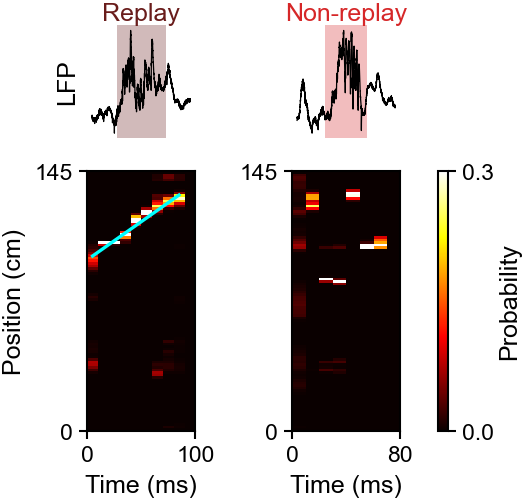

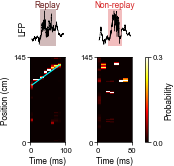

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import fig2_new_drawing as N            # fig2_new.py's drawing functions (copied)
N.LOGDIR = str(CSV)                        # they read their tables from this notebook's csv folder

# the notebook's data (its CSVs) and its ridge-line fit; events drawn: significant replay 1731 and
# non-significant event 934, left half
# ---- data (../csv) ----
# the submitted notebook's two events (PPP21 day 4): their decoded posteriors, intervals and the LFP around them
import fig2b_replay_fit_drawing as RF          # its ridge-line fit (Previous_Rv1 Fig2_B_Example_replay, copied)
ns = {'fit_replay_ridge_line': RF.fit_replay_ridge_line}
_iv = read_csv('event_intervals.csv').set_index('event')
EVENTS = [('Replay', dict(matrix=read_csv('replay_1731_matrix.csv').to_numpy(),
                          interval=_iv.loc['replay_1731', ['start', 'stop']].to_numpy()), N.DARK, True),
          ('Non-replay', dict(matrix=read_csv('nonreplay_934_left_matrix.csv').to_numpy(),
                              interval=_iv.loc['nonreplay_934_left', ['start', 'stop']].to_numpy()), N.RED, False)]
_lfp = read_csv('lfp_around_events.csv')
ts, lfp = _lfp.ts.to_numpy(), _lfp.lfp.to_numpy()
# ---- the same from the recordings, with analysis_scripts/: ----
# ns = F.rv1_namespace("Fig2_B_Example_replay", upto=9, defs_from=(9,))
# sig = ([dict(matrix=m, interval=iv) for m, iv in zip(ns["left_replay_matrix"], ns["left_intervals"])]
#        + [dict(matrix=m, interval=iv) for m, iv in zip(ns["right_replay_matrix"], ns["right_intervals"])])
# non = ns["non_sig_matrices"][934]
# EVENTS = [("Replay", sig[1731], N.DARK, True), ("Non-replay", dict(matrix=non["left"], interval=non["interval"]), N.RED, False)]
# ts, lfp = ns["ts"], ns["lfp"][:, min(ns["chan"], ns["lfp"].shape[1] - 1)]
DT, LFP_HALF = 0.01, 0.1                       # 10 ms decoding bins; LFP +-0.1 s around the event centre
POS_CM = 145                                   # the submitted panel's position axis: 0-145 cm over the decoded bins

F.final_style()
fig = plt.figure(figsize=(46 * F.MM, 44 * F.MM), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[1, 2.3], width_ratios=[1, 1, 0.09])
for j, (title, ev, col, ridge) in enumerate(EVENTS):
    M, iv = ev["matrix"], np.asarray(ev["interval"], float)
    n_pos, n_t = M.shape
    c = iv.mean()
    a, b = np.searchsorted(ts, c - LFP_HALF), np.searchsorted(ts, c + LFP_HALF)
    axl = fig.add_subplot(gs[0, j])
    axl.plot(ts[a:b] - c, lfp[a:b], "k", lw=0.3)
    axl.axvspan(iv[0] - c, iv[1] - c, color=col, alpha=0.3, lw=0)
    axl.set_title(title, color=col, pad=1)
    axl.set_xticks([]); axl.set_yticks([])
    for s in axl.spines.values():
        s.set_visible(False)
    if j == 0:
        axl.set_ylabel("LFP")
    axh = fig.add_subplot(gs[1, j])
    im = axh.imshow(M, aspect="auto", cmap="hot", origin="lower", extent=[0, n_t * DT, 0, n_pos], vmin=0, vmax=0.3,
                    interpolation="nearest")                   # crisp 10 ms bins
    if ridge:
        fit = ns["fit_replay_ridge_line"](M, min_col_mass_frac=0.2)
        if np.isfinite(fit["m"]):
            axh.plot((fit["x_fit"] + 0.5) * DT, fit["y_fit"], lw=0.8, color="cyan")
    axh.set_xticks([0, n_t * DT]); axh.set_xticklabels(["0", f"{n_t * DT * 1000:.0f}"]); axh.set_xlabel("Time (ms)")
    axh.set_yticks([0, n_pos]); axh.set_yticklabels(["0", f"{POS_CM}"])
    if j == 0:
        axh.set_ylabel("Position (cm)")
    for s in ("top", "right"):
        axh.spines[s].set_visible(True)
cax = fig.add_subplot(gs[1, 2])
fig.colorbar(im, cax=cax, ticks=[0, 0.3]).set_label("Probability", labelpad=1)
png = F.save(fig, "Fig2_B_replay_examples")
F.show(png)

## Fig 2B (curve) — example d2 and replay probability

PPP8 day 8, NREM, 180 s from 14 350.6 s: d2 (2024 Euclidean, AR p = 20) of the full window (grey) and with ripples excised (red), each z-scored within the plotted window, and replay probability (dark dashed; share of SWRs in a centred 30 s window with a replay event within ±80 ms of the ripple peak).

- Producer: `notebooks/exploration/revision/fig2c_example_excised.py` → `fig2c_example_excised.csv`.

saved figure_output\Fig2\Fig2_B_example_curve_full_and_bg_d2.svg / .png


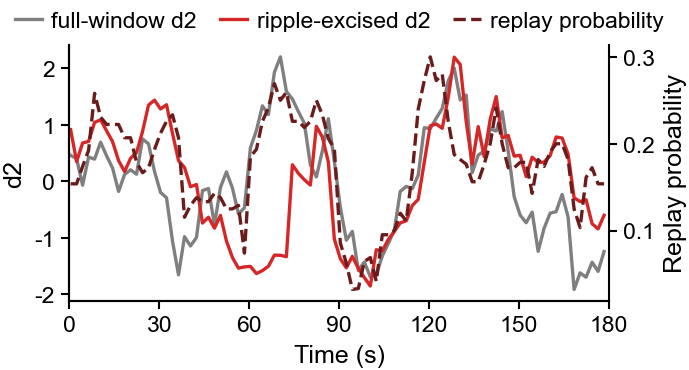

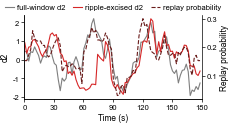

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import fig2_new_drawing as N            # fig2_new.py's drawing functions (copied)
N.LOGDIR = str(CSV)                        # they read their tables from this notebook's csv folder

# ---- data (../csv) ----
CURVE = CSV / "fig2c_example_excised.csv"   # fig2c_example_excised.py's plotted window
# ---- the same from the recordings, with analysis_scripts/: ----
# CURVE = os.path.join(F.REPO, "data", "revision", "log", "fig2c_example_excised.csv")   # the producer's plotted window
# RERUN = False                                  # True: rerun the producer first (reads one .mat from W:, read-only)
# if RERUN or not os.path.exists(CURVE):
#     import fig2c_example_excised as M
#     with F.retry_savefig():
#         M.main()
W = pd.read_csv(CURVE)

F.final_style()
fig, ax1 = plt.subplots(figsize=(60 * F.MM, 33 * F.MM), layout="constrained")
l1, = ax1.plot(W.time_seconds, W.d2_z, lw=0.8, color=N.GREY)                 # the producer's palette and lines
l1b, = ax1.plot(W.time_seconds, W.d2_excised_z, lw=0.8, color=N.RED)
ax1.set_ylabel("d2")                       # z-scored within the window: legend
ax2 = ax1.twinx()
l3, = ax2.plot(W.time_seconds, W.replay_prob, lw=0.8, color=N.DARK, ls="--")
ax2.set_ylabel("Replay probability"); ax2.spines["right"].set_visible(True); ax2.spines["top"].set_visible(False)
ax1.set_xlabel("Time (s)")
ax1.set_xticks([0, 30, 60, 90, 120, 150, 180]); ax1.set_xlim(0, 180)
ax1.legend([l1, l1b, l3], ["full-window d2", "ripple-excised d2", "replay probability"],
           loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, columnspacing=1.0)
png = F.save(fig, "Fig2_B_example_curve_full_and_bg_d2")
F.show(png)